# Concurso Ecuador sobre Malnutrición Infantil (IISEM2026 MCD)
**Examen parcial, Fundamentos de IA, Máster en Ciencia de Datos, Yachay Tech**

Realizado por: Alexander Fernández Pérez

**Objetivo:** Desarrollar un modelo de aprendizaje automático que prediga si un niño menor de 2 años corre riesgo de desnutrición

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings; warnings.filterwarnings('ignore')

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import lightgbm as lgb

SEED = 42
np.random.seed(SEED)
sns.set_theme(style='whitegrid')
pd.set_option('display.float_format', '{:.4f}'.format)

## 1. Carga de datos

In [4]:
RUTA = './'
X_train = pd.read_csv(RUTA + 'X_train_Kaggle.csv')
y_train = pd.read_csv(RUTA + 'y_train_Kaggle.csv')['alerta_desnutricion']
X_test  = pd.read_csv(RUTA + 'X_test_Kaggle.csv')
sample  = pd.read_csv(RUTA + 'sample_submission_malnutrition.csv')

print('Train:', X_train.shape, ' y:', y_train.shape, ' Test:', X_test.shape, ' Sample:', sample.shape)
X_train.head()

Train: (70000, 6)  y: (70000,)  Test: (30000, 6)  Sample: (30000, 2)


,edad_meses,sexo,region,nivel_educacion_madre,peso_kg,talla_cm
0,0,F,Costa,Secundaria,2.2435,47.3401
1,11,M,Insular,Secundaria,6.1572,67.5253
2,22,M,Costa,Superior,9.7813,86.6647
3,4,F,Sierra,Primaria,2.9723,61.0719
4,-4,F,Costa,Primaria,NaN,50.8982


## 2. Análisis exploratorio (EDA)
### 2.1 Balance

alerta_desnutricion
0   0.8999
1   0.1001
Name: proporción, dtype: float64


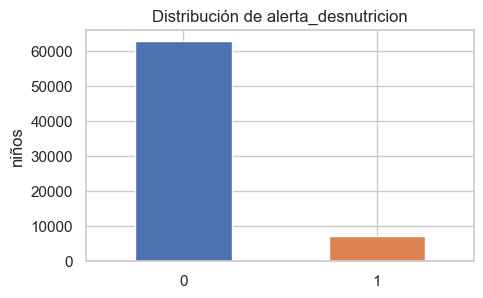

In [6]:
balance = y_train.value_counts(normalize=True).rename('proporción')
print(balance)

ax = y_train.value_counts().plot(kind='bar', color=['#4C72B0', '#DD8452'], figsize=(5,3))
ax.set_title('Distribución de alerta_desnutricion'); ax.set_xlabel(''); ax.set_ylabel('niños')
plt.xticks(rotation=0); plt.show()

### 2.2 Valores faltantes

In [7]:
faltantes = pd.DataFrame({'train_%': X_train.isna().mean()*100, 'test_%': X_test.isna().mean()*100})
faltantes

,train_%,test_%
edad_meses,0.0000,0.0000
sexo,0.0000,0.0000
region,0.0000,0.0000
nivel_educacion_madre,0.0000,0.0000
peso_kg,4.9557,4.9433
talla_cm,10.0700,9.8367


### 2.3 Inconsistencias en las variables numéricas

In [9]:
X_train[['edad_meses','peso_kg','talla_cm']].describe(percentiles=[.001,.01,.5,.99,.999]).T

,count,mean,std,min,0.1%,1%,50%,99%,99.9%,max
edad_meses,70000.0000,11.4595,8.2527,-12.0000,-11.0000,-5.0000,11.0000,28.0000,29.0000,29.0000
peso_kg,66531.0000,6.8800,4.6487,-0.8142,0.7010,1.6159,6.5231,30.2836,56.9538,59.9761
talla_cm,62951.0000,67.4800,11.9371,34.9046,41.9316,45.3484,67.3815,90.1705,93.4705,98.2136


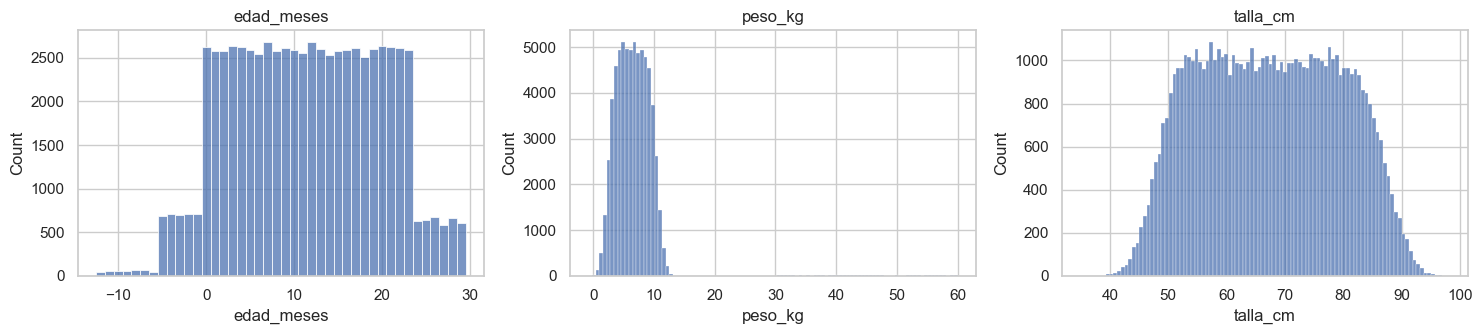

Edades negativas: 3921
Edades > 23 meses (dataset dice < 2 años): 3792
Pesos <= 0: 11
Pesos > 25 kg (imposible a esta edad): 673


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15,3.5))
sns.histplot(X_train.edad_meses, discrete=True, ax=axes[0]); axes[0].set_title('edad_meses')
sns.histplot(X_train.peso_kg, bins=100, ax=axes[1]); axes[1].set_title('peso_kg')
sns.histplot(X_train.talla_cm, bins=100, ax=axes[2]); axes[2].set_title('talla_cm')
plt.tight_layout(); plt.show()

print('Edades negativas:', (X_train.edad_meses < 0).sum())
print('Edades > 23 meses (dataset dice < 2 años):', (X_train.edad_meses > 23).sum())
print('Pesos <= 0:', (X_train.peso_kg <= 0).sum())
print('Pesos > 25 kg (imposible a esta edad):', (X_train.peso_kg > 25).sum())

Estas inconsistencias también aparecen en el test, así que **no podemos borrar filas del test**: tenemos que predecir todas.
La estrategia será marcar los valores imposibles como faltantes y crear *banderas* (variables 0/1) que indiquen la inconsistencia.

## 3. ¿Qué variables explican el target?
### 3.1 Variables categóricas
Calculamos la tasa de alerta (media de `y`) por categoría.

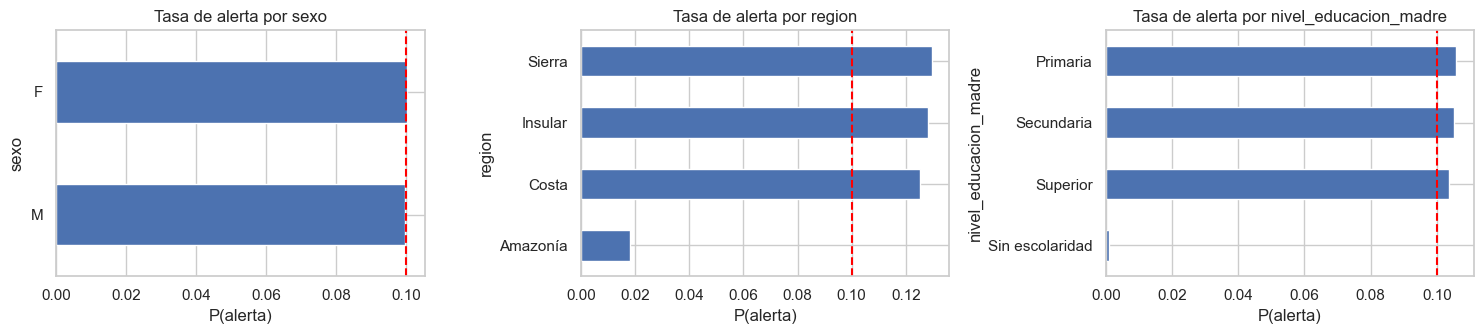

nivel_educacion_madre,Primaria,Secundaria,Sin escolaridad,Superior
region,,,,
Amazonía,0.0190,0.0190,0.0000,0.0190
Costa,0.1340,0.1300,0.0030,0.1310
Insular,0.1300,0.1400,0.0000,0.1290
Sierra,0.1400,0.1340,0.0000,0.1350


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15,3.5))
for ax, c in zip(axes, ['sexo','region','nivel_educacion_madre']):
    t = d.groupby(c)['y'].mean().sort_values()
    t.plot(kind='barh', ax=ax, color='#4C72B0'); ax.axvline(y_train.mean(), ls='--', c='red')
    ax.set_title(f'Tasa de alerta por {c}'); ax.set_xlabel('P(alerta)')
plt.tight_layout(); plt.show()

d.groupby(['region','nivel_educacion_madre'])['y'].mean().unstack().round(3)

**Lectura.**
- `sexo` no diferencia nada (≈10 % en ambos).
- `region`: la **Amazonía** tiene una tasa muy baja (~2 %); las demás regiones ~13 %.
- `nivel_educacion_madre`: **Sin escolaridad** casi nunca tiene alerta (~0 %); los demás ~10.5 %.

### 3.2 Variables antropométricas
La desnutrición crónica se define con la **talla para la edad** (z < −2 según la OMS) y la emaciación con el **peso para la talla**.
Construimos un *z-score empírico* por sexo y edad (mediana y dispersión robusta) para ver si el target sigue esa lógica.

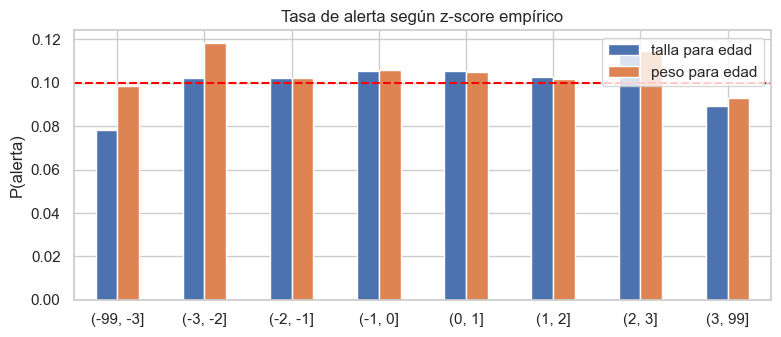

,talla para edad,peso para edad
"(-99, -3]",0.0781,0.0988
"(-3, -2]",0.1022,0.1183
"(-2, -1]",0.1020,0.1024
"(-1, 0]",0.1055,0.1058
"(0, 1]",0.1055,0.1050
"(1, 2]",0.1028,0.1018
"(2, 3]",0.1148,0.1148
"(3, 99]",0.0896,0.0929


In [13]:
dd = d[d.edad_meses >= 0].copy()
for v in ['talla_cm','peso_kg']:
    g = dd.groupby(['sexo','edad_meses'])[v]
    med = g.transform('median')
    iqr = g.transform(lambda x: x.quantile(.75) - x.quantile(.25)) / 1.349
    dd['z_' + v] = (dd[v] - med) / iqr

cortes = [-99,-3,-2,-1,0,1,2,3,99]
res = pd.concat({
    'talla para edad': dd.groupby(pd.cut(dd.z_talla_cm, cortes))['y'].mean(),
    'peso para edad':  dd.groupby(pd.cut(dd.z_peso_kg,  cortes))['y'].mean()}, axis=1)
res.plot(kind='bar', figsize=(9,3.5)); plt.axhline(y_train.mean(), ls='--', c='red')
plt.title('Tasa de alerta según z-score empírico'); plt.ylabel('P(alerta)'); plt.xticks(rotation=0); plt.show()
res

**Lectura.** La tasa de alerta es **plana (~10 %)** en todos los niveles de z-score. Los niños muy bajos para su edad (z < −2) **no** tienen más alertas.
Es decir, en este dataset el peso y la talla prácticamente **no aportan información** sobre la etiqueta.

## 4. Limpieza de variables
Aplicamos **la misma función** a train y test (para no introducir diferencias entre ambos):
1. Edad negativa → `edad_inconsistente` y edad = NaN. Edad > 23 → `edad_mayor_2a`.
2. Peso ≤ 0 o > 25 kg → `peso_inconsistente` y peso = NaN.
3. Faltantes originales.
4. IMC = peso / talla².
5. Categóricas como tipo `category` (LightGBM las maneja).

In [14]:
CATS = ['sexo', 'region', 'nivel_educacion_madre']

def preparar(df):
    df = df.copy()
    df['peso_falta']  = df.peso_kg.isna().astype(int)
    df['talla_falta'] = df.talla_cm.isna().astype(int)
    df['edad_inconsistente'] = (df.edad_meses < 0).astype(int)
    df['edad_mayor_2a']      = (df.edad_meses > 23).astype(int)
    df.loc[df.edad_meses < 0, 'edad_meses'] = np.nan
    malo = (df.peso_kg <= 0) | (df.peso_kg > 25)
    df['peso_inconsistente'] = malo.astype(int)
    df.loc[malo, 'peso_kg'] = np.nan
    df['imc'] = df.peso_kg / (df.talla_cm / 100) ** 2
    for c in CATS:
        df[c] = df[c].astype('category')
    return df

Xtr = preparar(X_train)
Xte = preparar(X_test)
NUM = [c for c in Xtr.columns if c not in CATS]
Xtr.head()

,edad_meses,sexo,region,nivel_educacion_madre,peso_kg,talla_cm,peso_falta,talla_falta,edad_inconsistente,edad_mayor_2a,peso_inconsistente,imc
0,0.0000,F,Costa,Secundaria,2.2435,47.3401,0,0,0,0,0,10.0106
1,11.0000,M,Insular,Secundaria,6.1572,67.5253,0,0,0,0,0,13.5036
2,22.0000,M,Costa,Superior,9.7813,86.6647,0,0,0,0,0,13.0230
3,4.0000,F,Sierra,Primaria,2.9723,61.0719,0,0,0,0,0,7.9692
4,NaN,F,Costa,Primaria,NaN,50.8982,1,0,1,0,0,NaN


## 5. Línea base y accuracy
Antes de entrenar modelos necesitamos una **línea base**: el clasificador que predice siempre la clase mayoritaria (0).
Si un modelo no supera esta línea base, no está aportando nada para la métrica del concurso.

In [15]:
acc_base = accuracy_score(y_train, np.zeros_like(y_train))
print(f'Accuracy prediciendo siempre 0: {acc_base:.4f}')

Accuracy prediciendo siempre 0: 0.8999


**Paradoja del accuracy:** con clases desbalanceadas, un modelo "tonto" logra un 90 % sin detectar ni un solo caso de alerta.
Desde salud pública ese modelo es inútil (sensibilidad = 0), pero la métrica del concurso no.

## 6. Modelos con validación cruzada estratificada
Usamos **5 folds estratificados** (cada fold conserva el 10 % de positivos).

Métricas:
- **Accuracy** (la del concurso, con umbral 0.5).
- **AUC-ROC**: mide si el modelo *ordena* bien a los niños por riesgo (0.5 = azar, 1 = perfecto). Sirve para saber si hay señal aunque el accuracy no se mueva.

In [16]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
y = y_train.values

def evaluar_oof(crear_modelo, X):
    oof = np.zeros(len(y))
    for tr, va in skf.split(X, y):
        m = crear_modelo()
        m.fit(X.iloc[tr], y[tr])
        oof[va] = m.predict_proba(X.iloc[va])[:, 1]
    return oof

# Preprocesamiento para modelos de sklearn: imputación + one-hot
prep = lambda: make_column_transformer(
    (make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), NUM),
    (OneHotEncoder(handle_unknown='ignore'), CATS))

modelos = {
    'Regresión logística': lambda: make_pipeline(prep(), LogisticRegression(max_iter=1000)),
    'Random Forest': lambda: make_pipeline(prep(), RandomForestClassifier(
        n_estimators=300, min_samples_leaf=50, n_jobs=-1, random_state=SEED)),
    'LightGBM': lambda: lgb.LGBMClassifier(
        n_estimators=250, learning_rate=0.02, num_leaves=31, min_child_samples=50,
        subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1),
}

OOF, filas = {}, []
for nombre, f in modelos.items():
    p = evaluar_oof(f, Xtr)
    OOF[nombre] = p
    filas.append({'modelo': nombre, 'accuracy (umbral 0.5)': accuracy_score(y, p > 0.5),
                  'AUC': roc_auc_score(y, p), 'prob. máxima': p.max(), 'n predichos = 1': int((p > 0.5).sum())})
filas.append({'modelo': 'Siempre 0 (línea base)', 'accuracy (umbral 0.5)': acc_base,
              'AUC': 0.5, 'prob. máxima': 0, 'n predichos = 1': 0})
resultados = pd.DataFrame(filas).set_index('modelo')
resultados

,accuracy (umbral 0.5),AUC,prob. máxima,n predichos = 1
modelo,,,,
Regresión logística,0.8999,0.6526,0.1815,0
Random Forest,0.8999,0.6534,0.2301,0
LightGBM,0.8999,0.6544,0.3428,0
Siempre 0 (línea base),0.8999,0.5000,0.0000,0


## 7. Teoría de decisión: ¿qué umbral maximiza el accuracy?
Para un niño con probabilidad real $p$ de alerta:
- si predecimos **1**, acertamos con probabilidad $p$;
- si predecimos **0**, acertamos con probabilidad $1-p$.

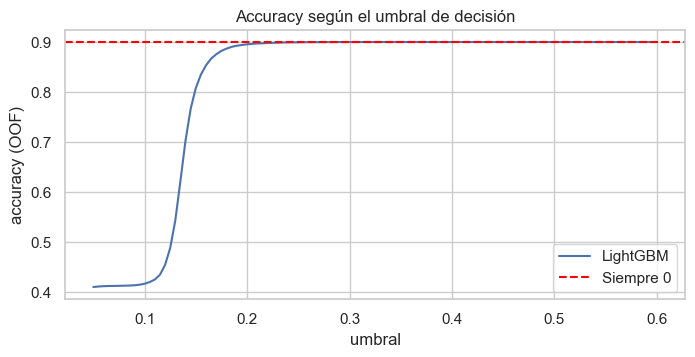

Mejor umbral: 0.345 -> accuracy 0.8999   (línea base 0.8999)


In [17]:
p = OOF['LightGBM']
umbrales = np.linspace(0.05, 0.6, 111)
accs = [accuracy_score(y, p > t) for t in umbrales]

plt.figure(figsize=(8,3.5))
plt.plot(umbrales, accs, label='LightGBM')
plt.axhline(acc_base, ls='--', c='red', label='Siempre 0')
plt.xlabel('umbral'); plt.ylabel('accuracy (OOF)'); plt.title('Accuracy según el umbral de decisión')
plt.legend(); plt.show()

mejor = umbrales[int(np.argmax(accs))]
print(f'Mejor umbral: {mejor:.3f} -> accuracy {max(accs):.4f}   (línea base {acc_base:.4f})')

**Lectura.** Bajar el umbral solo **empeora** el accuracy: cada niño adicional que marcamos como 1 tiene, como mucho, ~15–30 % de probabilidad real de alerta, así que nos equivocamos más de lo que acertamos. El máximo se alcanza cuando el modelo predice 0 para todos.

### 7.1 Importancia de variables (LightGBM entrenado con todo el train)

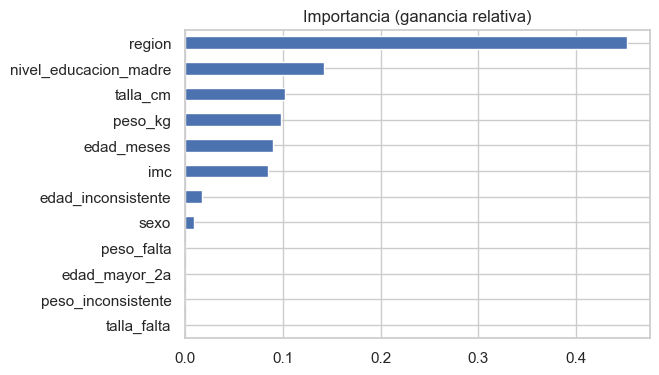

In [19]:
final = modelos['LightGBM']().fit(Xtr, y)
imp = pd.Series(final.booster_.feature_importance('gain'), index=Xtr.columns).sort_values()
(imp / imp.sum()).plot(kind='barh', figsize=(6,4), title='Importancia (ganancia relativa)'); plt.show()

## 8. Predicción final
Usamos el modelo LightGBM entrenado con todos los datos; como ningún niño supera 0.5, el envío queda en 0 para todos (lo verificamos).

**Accuracy esperado en el leaderboard:** ≈ 1 − (proporción de alertas en el test) ≈ **0.90**. Con 30 000 niños, la variación por azar es de unas ±0.2 décimas porcentuales.

In [20]:
p_test = final.predict_proba(Xte)[:, 1]
print('Probabilidad máxima en test:', round(p_test.max(), 4))
pred = (p_test > 0.5).astype(int)

submission = pd.DataFrame({'ID': sample['ID'], 'alerta_desnutricion': pred})
assert len(submission) == len(X_test) == len(sample)
assert list(submission.columns) == list(sample.columns)
submission.to_csv('submission_alerta_desnutricion.csv', index=False)
print(submission['alerta_desnutricion'].value_counts())
submission.head()

Probabilidad máxima en test: 0.3178
alerta_desnutricion
0    30000
Name: count, dtype: int64


,ID,alerta_desnutricion
0,1,0
1,2,0
2,3,0
3,4,0
4,5,0


## 9. Conclusiones
1. **Datos.** Sintéticos, desbalanceados (10 % de alertas), con faltantes aleatorios e inconsistencias intencionales (edades negativas, pesos imposibles). Se limpiaron, sin borrar filas.
2. **Señal.** Solo `region` (Amazonía ≈ 2 %) y `nivel_educacion_madre` (Sin escolaridad ≈ 0 %) cambian la tasa de alerta.
3. **Modelos.** Regresión logística, Random Forest y LightGBM alcanzan AUC ≈ 0.65, pero ningún niño llega a probabilidad 0.5.
4. Un modelo que nunca alerta tiene accuracy alto pero sensibilidad 0: en una política real de desnutrición infantil no detectaría a ningún niño en riesgo. Para un uso real se debería evaluar con recall, F1 o AUC, y elegir el umbral según el costo de no detectar un caso. Aquí seguimos la métrica oficial del concurso, pero es importante saber sus límites.